Running Original Baseline...


/clusterfs/opt/qupy/lib/python3.13/site-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


Running wide Gaussian...
Running narrow Gaussian...
Running step function...
Computing thermodynamic observables (Energy Stored, Charging Power, Ergotropy)...
Plotting laser pulse profiles...


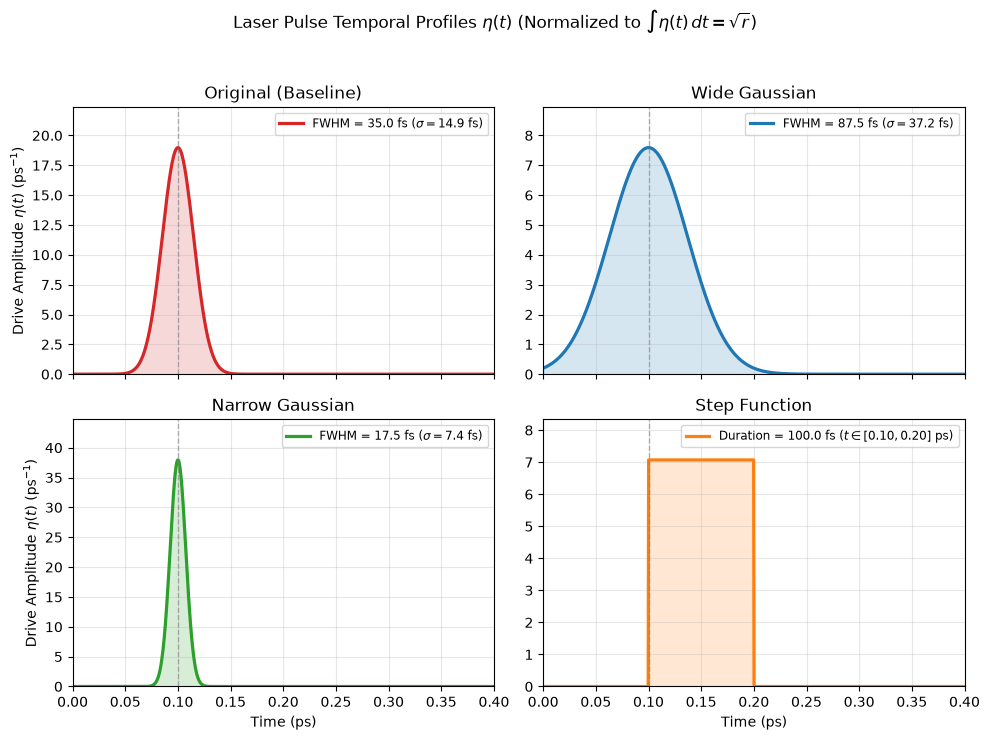

Plotting population dynamics...


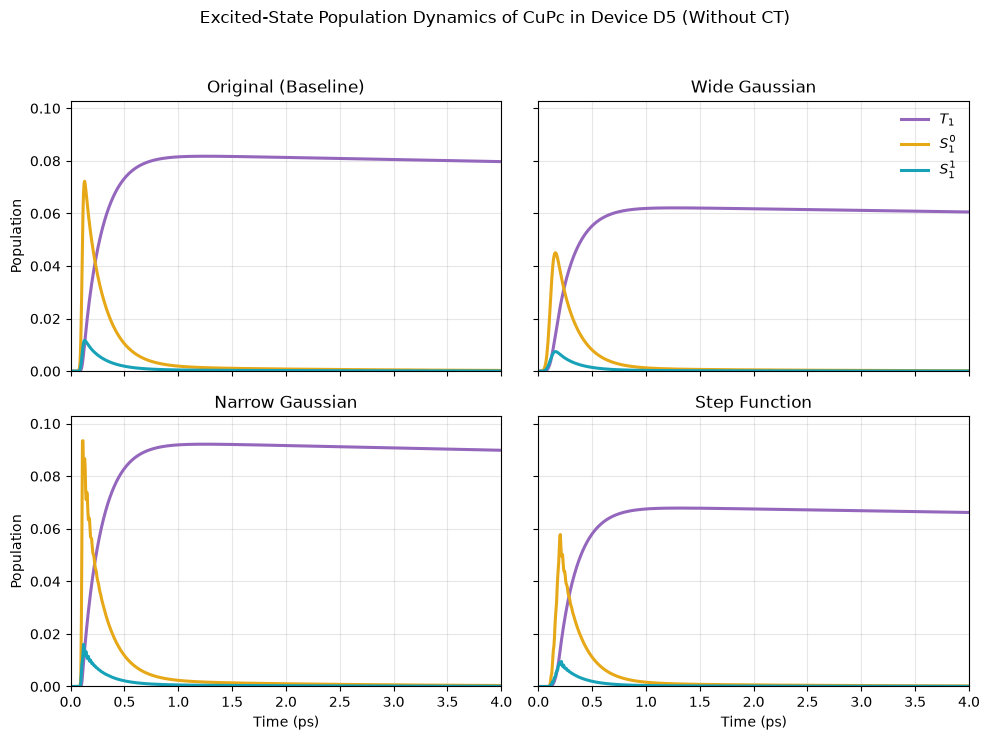

Plotting Energy Stored, Charging Power, and Ergotropy...


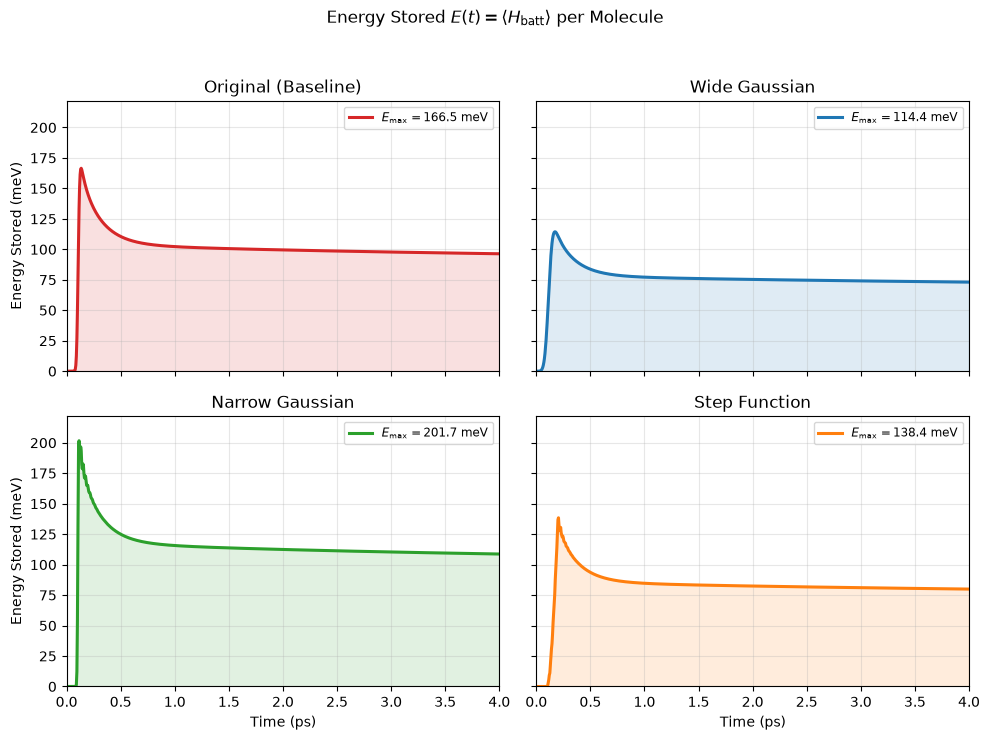

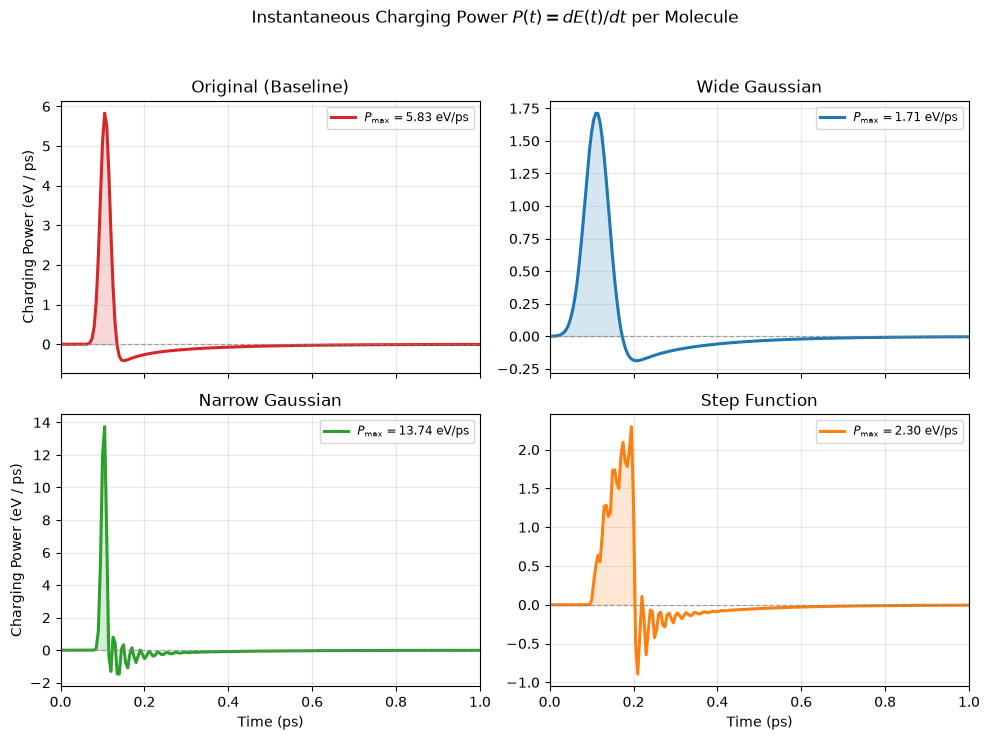

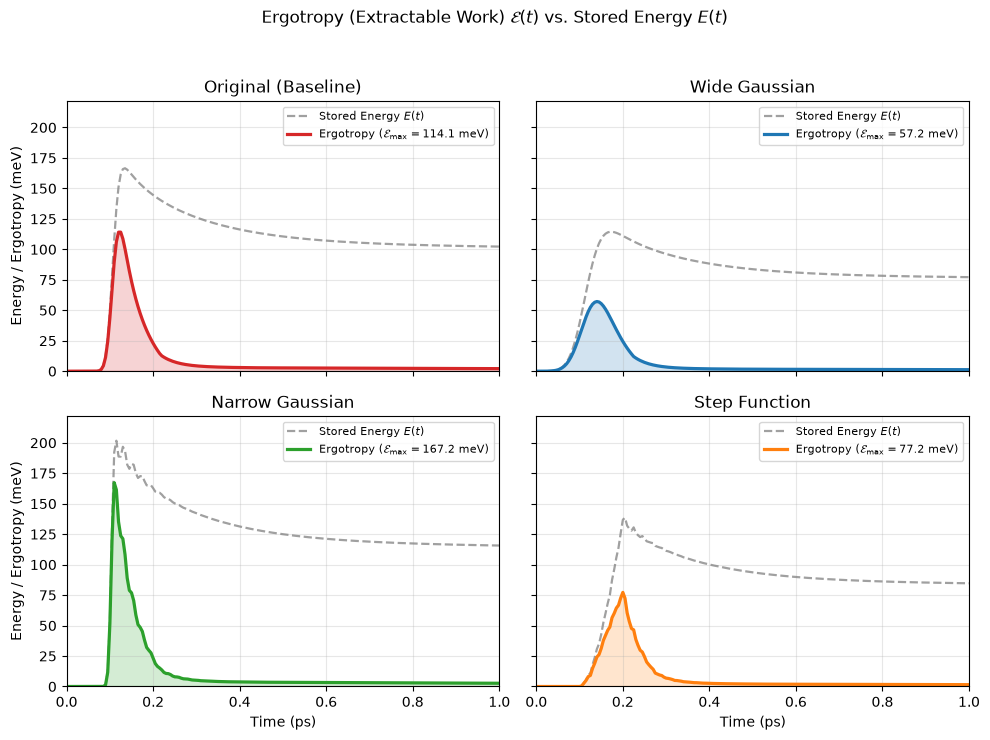

All plots saved successfully.

Saving simulation results...
-> Saved simulation data to 'protocols_sim_results.npz'
-> Saved summary CSV to 'protocols_sim_results.csv'


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# ----------------------------- physical constants ---------------------------
hbar = 6.582119569e-4          # eV * ps

# ------------------------- device D5 parameters -----------------------------
Delta1, Delta2, DeltaT, Deltac = 1.80, 1.98, 1.20, 1.82   # eV (CT removed)
g_bare = 500e-9                # eV
N      = 5.0e10                
G      = g_bare * np.sqrt(N)   # collective coupling (eV)

kappa, gamma_m, gamma_T = 29.0, 0.5, 0.01     # ps^-1
gamma_z, gamma_ISC      = 20.0, 5.0           # ps^-1

# Pulse parameters
r          = 0.5
t0         = 0.10                                       # ps
sigma_orig = (35.0 / (2*np.sqrt(2*np.log(2)))) * 1e-3   # ~0.01486 ps

# Define modified pulse parameters for comparison
sigma_wide   = sigma_orig * 2.5   # Wide pulse
sigma_narrow = sigma_orig * 0.5   # Narrow pulse

M_pol = np.array([[Deltac, G,      G     ],
                  [G,      Delta1, 0.0   ],
                  [G,      0.0,    Delta2]])
nu = np.linalg.eigvalsh(M_pol)[0]

d1, d2, dc = (Delta1 - nu)/hbar, (Delta2 - nu)/hbar, (Deltac - nu)/hbar
Gw = G / hbar

def build_model():
    """Operators, Hamiltonian, collapse and measurement operators (without CT)."""
    Na, Nb = 5, 3              
    Ia, Ib, I2 = qt.qeye(Na), qt.qeye(Nb), qt.qeye(2)

    def emb(op, slot):
        ops = [Ia, Ib, Ib, I2, I2, I2]
        ops[slot] = op
        return qt.tensor(*ops)

    a   = emb(qt.destroy(Na), 0)            
    b1  = emb(qt.destroy(Nb), 1)            
    b2  = emb(qt.destroy(Nb), 2)            
    dk1 = emb(qt.destroy(2), 3)            
    dk2 = emb(qt.destroy(2), 4)            
    Tm  = emb(qt.destroy(2), 5)            
    
    H0 = (dc * a.dag()*a + d1 * b1.dag()*b1 + d2 * b2.dag()*b2
          + Gw * (a.dag()*(b1 + b2) + (b1.dag() + b2.dag())*a))
    Hdrive = 1j * (a.dag() - a)            

    c_ops = [np.sqrt(kappa)     * a,
             np.sqrt(gamma_m)   * b1,               
             np.sqrt(gamma_m)   * b2,               
             np.sqrt(gamma_m)   * dk1,              
             np.sqrt(gamma_m)   * dk2,              
             np.sqrt(gamma_T)   * Tm,               
             np.sqrt(gamma_z)   * dk1.dag()*b1,     
             np.sqrt(gamma_z)   * dk2.dag()*b2,
             np.sqrt(gamma_ISC) * Tm.dag()*b1,      
             np.sqrt(gamma_ISC) * Tm.dag()*b2,
             np.sqrt(gamma_ISC) * Tm.dag()*dk1,     
             np.sqrt(gamma_ISC) * Tm.dag()*dk2]             

    e_ops = [b1.dag()*b1 + dk1.dag()*dk1,           # <X11>  (S1^0)
             b2.dag()*b2 + dk2.dag()*dk2,           # <X22>  (S1^1)
             Tm.dag()*Tm,                           # <XTT>  (T1)
             a.dag()*a]                             # photons per molecule

    H_batt = (Delta1 * (b1.dag()*b1 + dk1.dag()*dk1)
              + Delta2 * (b2.dag()*b2 + dk2.dag()*dk2)
              + DeltaT * Tm.dag()*Tm)

    # Molecular battery Hamiltonian (tracing out cavity slot 0) for ergotropy calculation
    b1_mol  = qt.tensor(qt.destroy(Nb), Ib, I2, I2, I2)
    b2_mol  = qt.tensor(Ib, qt.destroy(Nb), I2, I2, I2)
    dk1_mol = qt.tensor(Ib, Ib, qt.destroy(2), I2, I2)
    dk2_mol = qt.tensor(Ib, Ib, I2, qt.destroy(2), I2)
    Tm_mol  = qt.tensor(Ib, Ib, I2, I2, qt.destroy(2))
    H_batt_mol = (Delta1 * (b1_mol.dag()*b1_mol + dk1_mol.dag()*dk1_mol)
                  + Delta2 * (b2_mol.dag()*b2_mol + dk2_mol.dag()*dk2_mol)
                  + DeltaT * Tm_mol.dag()*Tm_mol)

    psi0 = qt.tensor(qt.basis(Na, 0), qt.basis(Nb, 0), qt.basis(Nb, 0),
                     qt.basis(2, 0), qt.basis(2, 0), qt.basis(2, 0))
    return H0, Hdrive, c_ops, e_ops, psi0, H_batt, H_batt_mol


# Drive functions (all normalized to the same total integral sqrt(r))
def eta_orig(t, args=None):
    return (np.sqrt(r) / (sigma_orig * np.sqrt(2*np.pi))) * np.exp(-(t - t0)**2 / (2*sigma_orig**2))

def eta_wide(t, args=None):
    return (np.sqrt(r) / (sigma_wide * np.sqrt(2*np.pi))) * np.exp(-(t - t0)**2 / (2*sigma_wide**2))

def eta_narrow(t, args=None):
    return (np.sqrt(r) / (sigma_narrow * np.sqrt(2*np.pi))) * np.exp(-(t - t0)**2 / (2*sigma_narrow**2))

def eta_step(t, args=None):
    # Step function that turns on abruptly at midpoint t0 and stays on for 0.1 ps
    step_duration = 0.10
    return (np.sqrt(r) / step_duration) if t0 <= t <= (t0 + step_duration) else 0.0


H0, Hdrive, c_ops, e_ops, psi0, H_batt, H_batt_mol = build_model()
eps_batt_sorted = np.sort(np.real(H_batt_mol.eigenenergies()))

tlist = np.linspace(0.0, 4.0, 801)     # ps
# max_step wajib: tanpa ini solver adaptif bisa "melompati" pulsa sempit (sigma ~7 fs)
opts = {"atol": 1e-9, "rtol": 1e-7, "nsteps": 1000000, "store_states": True,
        "max_step": sigma_narrow / 5}   # ~1.5 fs

print("Running Original Baseline...")
res_orig = qt.mesolve([H0, [Hdrive, eta_orig]], psi0, tlist, c_ops, e_ops=e_ops, options=opts)

print("Running wide Gaussian...")
res_wide = qt.mesolve([H0, [Hdrive, eta_wide]], psi0, tlist, c_ops, e_ops=e_ops, options=opts)

print("Running narrow Gaussian...")
res_narrow = qt.mesolve([H0, [Hdrive, eta_narrow]], psi0, tlist, c_ops, e_ops=e_ops, options=opts)

print("Running step function...")
res_step = qt.mesolve([H0, [Hdrive, eta_step]], psi0, tlist, c_ops, e_ops=e_ops, options=opts)


def compute_thermodynamics(res, tlist, eps_sorted):
    """Compute stored energy E(t), charging power P(t), and ergotropy E_ext(t)."""
    P_S10 = np.real(res.expect[0])
    P_S11 = np.real(res.expect[1])
    P_T1  = np.real(res.expect[2])
    
    # Stored energy E(t) = <H_batt> (in eV)
    E_stored = Delta1 * P_S10 + Delta2 * P_S11 + DeltaT * P_T1
    # Instantaneous charging power P(t) = dE(t)/dt (in eV/ps)
    P_charge = np.gradient(E_stored, tlist)
    
    # Ergotropy (extractable work) of the molecular battery subsystem:
    # W_ext(t) = Tr[rho_mol(t) H_batt_mol] - sum_k r_k(t) * eps_k
    ergotropy = np.zeros(len(tlist))
    for i, state in enumerate(res.states):
        rho_mol = state.ptrace([1, 2, 3, 4, 5])
        r_vals = np.sort(np.real(rho_mol.eigenenergies()))[::-1]
        ergotropy[i] = max(0.0, E_stored[i] - np.sum(r_vals * eps_sorted))
        
    return E_stored, P_charge, ergotropy


print("Computing thermodynamic observables (Energy Stored, Charging Power, Ergotropy)...")
thermo_orig   = compute_thermodynamics(res_orig,   tlist, eps_batt_sorted)
thermo_wide   = compute_thermodynamics(res_wide,   tlist, eps_batt_sorted)
thermo_narrow = compute_thermodynamics(res_narrow, tlist, eps_batt_sorted)
thermo_step   = compute_thermodynamics(res_step,   tlist, eps_batt_sorted)

# ------------------------------------------------------------------------------
# 1. PLOT LASER PULSE PROFILES (BEFORE POPULATION PLOT)
# ------------------------------------------------------------------------------
print("Plotting laser pulse profiles...")
t_pulse = np.linspace(0.0, 0.40, 1000)
pulse_list = [
    ("Original (Baseline)", [eta_orig(t) for t in t_pulse],   "#d62728", f"FWHM = 35.0 fs ($\\sigma = {sigma_orig*1e3:.1f}$ fs)"),
    ("Wide Gaussian",       [eta_wide(t) for t in t_pulse],   "#1f77b4", f"FWHM = 87.5 fs ($\\sigma = {sigma_wide*1e3:.1f}$ fs)"),
    ("Narrow Gaussian",     [eta_narrow(t) for t in t_pulse], "#2ca02c", f"FWHM = 17.5 fs ($\\sigma = {sigma_narrow*1e3:.1f}$ fs)"),
    ("Step Function",       [eta_step(t) for t in t_pulse],   "#ff7f0e", "Duration = 100.0 fs ($t \\in [0.10, 0.20]$ ps)"),
]

fig_pulse, axs_p = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True)
fig_pulse.suptitle(r"Laser Pulse Temporal Profiles $\eta(t)$ (Normalized to $\int \eta(t)\,dt = \sqrt{r}$)", y=0.98)

for ax, (title, y_vals, color, label_str) in zip(axs_p.flat, pulse_list):
    y_arr = np.array(y_vals)
    ax.plot(t_pulse, y_arr, color=color, lw=2.3, label=label_str)
    ax.fill_between(t_pulse, 0, y_arr, color=color, alpha=0.18)
    ax.axvline(t0, color="gray", ls="--", lw=1.0, alpha=0.6)
    ax.set_title(title)
    ax.set_xlim(0.0, 0.40)
    ax.set_ylim(bottom=0, top=y_arr.max() * 1.18)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)

axs_p[1, 0].set_xlabel("Time (ps)")
axs_p[1, 1].set_xlabel("Time (ps)")
axs_p[0, 0].set_ylabel(r"Drive Amplitude $\eta(t)$ ($\mathrm{ps}^{-1}$)")
axs_p[1, 0].set_ylabel(r"Drive Amplitude $\eta(t)$ ($\mathrm{ps}^{-1}$)")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("pulse_profiles_comparison.png", dpi=200)
plt.show()

# ------------------------------------------------------------------------------
# 2. PLOT POPULATION DYNAMICS (WITHOUT CT)
# ------------------------------------------------------------------------------
print("Plotting population dynamics...")
def plot_populations(ax, res, title):
    P_S10 = np.real(res.expect[0])
    P_S11 = np.real(res.expect[1])
    P_T1  = np.real(res.expect[2])
    ax.plot(tlist, P_T1,  color="#9467bd", lw=2.2, label=r"$T_1$")
    ax.plot(tlist, P_S10, color="#e6a817", lw=2.2, label=r"$S_1^0$")
    ax.plot(tlist, P_S11, color="#17a2b8", lw=2.2, label=r"$S_1^1$")
    ax.set_title(title)
    ax.set_xlim(0, 4)
    ax.grid(True, alpha=0.3)

fig_pop, axs_pop = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True, sharey=True)
fig_pop.suptitle("Excited-State Population Dynamics of CuPc in Device D5 (Without CT)", y=0.98)

plot_populations(axs_pop[0, 0], res_orig,   "Original (Baseline)")
plot_populations(axs_pop[0, 1], res_wide,   "Wide Gaussian")
plot_populations(axs_pop[1, 0], res_narrow, "Narrow Gaussian")
plot_populations(axs_pop[1, 1], res_step,   "Step Function")

# Batas y dihitung dari semua kasus agar tidak ada kurva yang terpotong (sharey=True)
pop_max = max(np.real(res.expect[k]).max()
              for res in (res_orig, res_wide, res_narrow, res_step) for k in range(3))
axs_pop[0, 0].set_ylim(0, pop_max * 1.1)

axs_pop[1, 0].set_xlabel("Time (ps)")
axs_pop[1, 1].set_xlabel("Time (ps)")
axs_pop[0, 0].set_ylabel("Population")
axs_pop[1, 0].set_ylabel("Population")
axs_pop[0, 1].legend(loc="upper right", frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("population_dynamics_comparison.png", dpi=200)
plt.show()

# ------------------------------------------------------------------------------
# 3. PLOT ENERGY STORED, CHARGING POWER, AND ERGOTROPY (AFTER POPULATION PLOT)
# ------------------------------------------------------------------------------
print("Plotting Energy Stored, Charging Power, and Ergotropy...")
thermo_items = [
    ("Original (Baseline)", thermo_orig,   "#d62728"),
    ("Wide Gaussian",       thermo_wide,   "#1f77b4"),
    ("Narrow Gaussian",     thermo_narrow, "#2ca02c"),
    ("Step Function",       thermo_step,   "#ff7f0e"),
]

# 3a. Energy Stored E(t)
E_lim = 1.1 * 1e3 * max(th[0].max() for _, th, _ in thermo_items)   # meV
fig_e, axs_e = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True, sharey=True)
fig_e.suptitle(r"Energy Stored $E(t) = \langle H_{\mathrm{batt}} \rangle$ per Molecule", y=0.98)
for ax, (title, (E_st, _, _), color) in zip(axs_e.flat, thermo_items):
    E_meV = E_st * 1e3
    ax.plot(tlist, E_meV, color=color, lw=2.2, label=f"$E_{{\\max}} = {E_meV.max():.1f}$ meV")
    ax.fill_between(tlist, 0, E_meV, color=color, alpha=0.14)
    ax.set_title(title)
    ax.set_xlim(0, 4)
    ax.set_ylim(0, E_lim)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)
axs_e[1, 0].set_xlabel("Time (ps)")
axs_e[1, 1].set_xlabel("Time (ps)")
axs_e[0, 0].set_ylabel("Energy Stored (meV)")
axs_e[1, 0].set_ylabel("Energy Stored (meV)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("energy_stored_comparison.png", dpi=200)
plt.show()

# 3b. Charging Power P(t)
fig_p, axs_pw = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True)
fig_p.suptitle(r"Instantaneous Charging Power $P(t) = dE(t)/dt$ per Molecule", y=0.98)
for ax, (title, (_, P_ch, _), color) in zip(axs_pw.flat, thermo_items):
    ax.plot(tlist, P_ch, color=color, lw=2.2, label=f"$P_{{\\max}} = {P_ch.max():.2f}$ eV/ps")
    ax.fill_between(tlist, 0, P_ch, where=(P_ch >= 0), color=color, alpha=0.18)
    ax.axhline(0, color="gray", ls="--", lw=0.9, alpha=0.7)
    ax.set_title(title)
    ax.set_xlim(0, 1.0)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)
axs_pw[1, 0].set_xlabel("Time (ps)")
axs_pw[1, 1].set_xlabel("Time (ps)")
axs_pw[0, 0].set_ylabel("Charging Power (eV / ps)")
axs_pw[1, 0].set_ylabel("Charging Power (eV / ps)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("charging_power_comparison.png", dpi=200)
plt.show()

# 3c. Ergotropy (Extractable Work)
fig_erg, axs_erg = plt.subplots(2, 2, figsize=(10, 7.5), sharex=True, sharey=True)
fig_erg.suptitle(r"Ergotropy (Extractable Work) $\mathcal{E}(t)$ vs. Stored Energy $E(t)$", y=0.98)
for ax, (title, (E_st, _, Erg), color) in zip(axs_erg.flat, thermo_items):
    E_meV = E_st * 1e3
    Erg_meV = Erg * 1e3
    ax.plot(tlist, E_meV, color="gray", ls="--", lw=1.6, alpha=0.75, label="Stored Energy $E(t)$")
    ax.plot(tlist, Erg_meV, color=color, lw=2.3, label=f"Ergotropy ($\\mathcal{{E}}_{{\\max}} = {Erg_meV.max():.1f}$ meV)")
    ax.fill_between(tlist, 0, Erg_meV, color=color, alpha=0.20)
    ax.set_title(title)
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0, E_lim)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", frameon=True, fontsize=8.2)
axs_erg[1, 0].set_xlabel("Time (ps)")
axs_erg[1, 1].set_xlabel("Time (ps)")
axs_erg[0, 0].set_ylabel("Energy / Ergotropy (meV)")
axs_erg[1, 0].set_ylabel("Energy / Ergotropy (meV)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("ergotropy_comparison.png", dpi=200)
plt.show()
print("All plots saved successfully.")

# ------------------------------------------------------------------------------
# 4. SAVE SIMULATION RESULTS
# ------------------------------------------------------------------------------
print("\nSaving simulation results...")
eV_to_J = 1.602176634e-19
ps_to_s = 1.0e-12

cases_data = [
    ("Original Baseline", res_orig,   thermo_orig),
    ("Wide Gaussian",    res_wide,   thermo_wide),
    ("Narrow Gaussian",  res_narrow, thermo_narrow),
    ("Step Function",    res_step,   thermo_step),
]

save_dict = {"tlist": tlist}
csv_columns = [tlist]
csv_headers = ["time_ps"]

for name, res, (E_st, P_ch, Erg) in cases_data:
    P_S10 = np.real(res.expect[0])
    P_S11 = np.real(res.expect[1])
    P_T1  = np.real(res.expect[2])
    n_ph  = np.real(res.expect[3])
    
    E_meV = E_st * 1e3
    Erg_meV = Erg * 1e3
    E_pass_meV = np.maximum(0.0, E_meV - Erg_meV)
    
    # Instantaneous charging power for N-molecule battery ensemble (Watts)
    P_inst_total_W = np.gradient(N * E_st * eV_to_J, tlist * ps_to_s)
    
    # Save into dictionary for .npz
    save_dict[f"{name}_P_S10"] = P_S10
    save_dict[f"{name}_P_S11"] = P_S11
    save_dict[f"{name}_P_T1"]  = P_T1
    save_dict[f"{name}_n_ph"]  = n_ph
    save_dict[f"{name}_E_eV"]  = E_st
    save_dict[f"{name}_E_meV"] = E_meV
    save_dict[f"{name}_E_passive_meV"] = E_pass_meV
    save_dict[f"{name}_P_charge_eV_ps"] = P_ch
    save_dict[f"{name}_P_inst_total_W"] = P_inst_total_W
    save_dict[f"{name}_Ergotropy_eV"]  = Erg
    save_dict[f"{name}_Ergotropy_meV"] = Erg_meV
    
    # Prepare columns for .csv export
    tag = name.replace(" ", "_")
    csv_columns.extend([P_S10, P_S11, P_T1, n_ph, E_meV, P_ch, Erg_meV])
    csv_headers.extend([
        f"{tag}_S10", f"{tag}_S11", f"{tag}_T1", f"{tag}_n_ph",
        f"{tag}_E_meV", f"{tag}_P_eV_ps", f"{tag}_Erg_meV"
    ])

# 1. Simpan dalam format terkompresi NumPy (.npz)
np.savez_compressed("protocols_sim_results.npz", **save_dict)
print("-> Saved simulation data to 'protocols_sim_results.npz'")

# 2. Simpan dalam format tabel CSV (.csv) untuk analisis spreadsheet/Origin
csv_matrix = np.column_stack(csv_columns)
np.savetxt(
    "protocols_sim_results.csv",
    csv_matrix,
    delimiter=",",
    header=",".join(csv_headers),
    comments=""
)
print("-> Saved summary CSV to 'protocols_sim_results.csv'")


| Variasi Pulsa | Durasi / Lebar Pulsa | $\varepsilon_{\max}$ (meV) | $P_{\max}$ (eV/ps) | $E_{\max}$ (meV) | Rasio ($\varepsilon_{\max} / E_{\max}$) | Populasi Stabil ($T_1$) ($t = 1\text{ ps}$) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| Original (Baseline) | FWHM = 35.0 fs<br>($\sigma \approx 14.9\text{ fs}$) | 166.51 | 5.83 | 114.07 | 68.5% | 0.0816 |
| Wide Gaussian | FWHM = 87.5 fs<br>($\sigma \approx 37.2\text{ fs}$) | 114.39 | 1.71 | 57.17 | 50.0% | 0.0621 |
| Narrow Gaussian | FWHM = 17.5 fs<br>($\sigma \approx 7.4\text{ fs}$) | 201.65 | 13.74 | 167.17 | 82.9% | 0.0919 |
| Step Function | $\Delta t = 100.0\text{ fs}$<br>($t \in [0.10, 0.20]\text{ ps}$) | 138.46 | 2.30 | 77.21 | 55.8% | 0.0679 |